> Notebook-friendly copy of `part-II/3.5-wildfire-susceptibility-mapping-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- Préparation de l'environnement (générée automatiquement, hors exercice) ---
# Sur Colab/Kaggle, certains paquets ne sont pas installés par défaut.
# Si tout est déjà installé, cette cellule ne fait rien.
import importlib.util   # outils pour vérifier si un module Python est disponible
import subprocess       # permet de lancer une commande système (ici : pip)
import sys              # donne accès à l'interpréteur Python en cours (sys.executable)

# Pour chaque module requis (geopandas et pooch) ...
for module, package in {"geopandas": "geopandas", "pooch": "pooch"}.items():
    # ... si le module est introuvable ...
    if importlib.util.find_spec(module) is None:
        # ... on l'installe silencieusement (-q) avec pip ; check=True lève une erreur si l'installation échoue
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 3.5) (Exercises) Wildfire Susceptibility Mapping

---



**Credits**

This online tutorial would not be possible without invaluable contributions from [Andrea Trucchia](https://www.researchgate.net/profile/Andrea-Trucchia) (reduced data, methods), [Giorgio Meschi](https://www.linkedin.com/in/giorgio-meschi-86216b180/) (code, methods), and [Marj Tonini](https://www.researchgate.net/profile/Marj-Tonini-2) (presentation, methods). The methodology builds upon the following article:

[Trucchia, A.; Meschi, G.; Fiorucci, P.; Gollini, A.; Negro, D., Defining Wildfire Susceptibility Maps in Italy for Understanding Seasonal Wildfire Regimes at the National Level, *Fire*, (2022)](https://www.mdpi.com/2571-6255/5/1/30)

which generalizes the study below from the Liguria region (our case study) to all of Italy:

[Tonini, Marj, et al. "A machine learning-based approach for wildfire susceptibility mapping. The case study of the Liguria region in Italy." *Geosciences* 10.3 (2020): 105.](https://www.mdpi.com/2076-3263/10/3/105)



---

In week 3's final notebook, we will train classifiers on real [wildfire](https://en.wikipedia.org/wiki/Wildfire) data to map the fire risk in different regions of Italy. To keep the data size manageable, we will focus on the coastal [Liguria region](https://en.wikipedia.org/wiki/Liguria) that experiences a lot of wildfires, especially during the winter.

**🎯 Learning objectives**

- Use classification methods for environmental risk analysis
- Train classifiers on real data to map wildfire susceptibility in Liguria, Italy
- Benchmark the classifiers with scikit-learn's confusion matrix
- Run a sensitivity analysis to see how predictions change with season and input selection

## Machine Learning for Environmental Risk Analysis

For environmental sciences practioners, one of the scenarios where machine learning can be particularly useful is risk analysis. Environmental risk analysis involves predicting where potential hazards may occur; it also involves understanding why some regions are more vulnerable to hazards than others. Machine learning models can be useful for these tasks because they can analyze large datasets containing different environmental predictors (e.g., weather conditions, soil conditions etc.) in an effective manner. By learning the hidden links between predictors and hazard risks, we may also gain new insights on what predictors or patterns are useful for creating early hazard warning systems.

In this exercise, we ask you to use the machine learning classifiers we learned in this chapter to recreate wildfire susceptibility maps for the Liguria region of Italy. The basic idea is to use ML classifiers to analyze a dataset with observations in weather conditions, vegetation cover, and topography information. The goal will be to understand how different factors enhance or reduce the probability of firefire in Liguria, which can help authorities and decision-makers to apply resources to critical areas for hazard prevention.

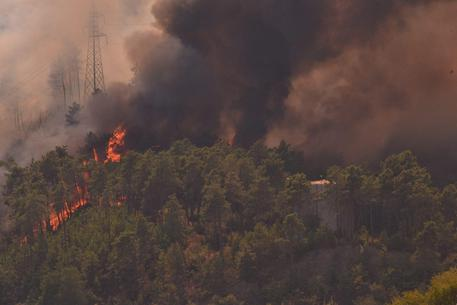

**Caption**: A wildfire in Italy. Can we predict which locations are most susceptible to wildfires using simple classifiers? 🔥

**Source**: [ANSA](https://www.ansa.it/english/news/2015/08/14/wildfires-in-italy-up-120-this-summer-on-past-two-years_f6e4eff7-ac07-4f9e-aa5a-e61f8c2ad7f2.html)

Let's start by downloading and loading the datasets into memory using the [`pooch`](https://pypi.org/project/pooch/) and [`GeoPandas`](https://geopandas.org/en/stable/) libraries:

In [2]:
# Installe geopandas (bibliothèque pour les données géographiques) dans l'environnement du notebook
%pip install geopandas

In [3]:
import geopandas as gpd   # tableaux de données avec géométrie (points, polygones) pour l'analyse spatiale
import numpy as np        # calcul numérique
import pickle             # lecture de fichiers .pkl (objets Python sauvegardés)
import pooch              # téléchargement de fichiers avec vérification d'intégrité

In [12]:
# Correctif : les fichiers pickle ont été créés avec pandas < 2.0, qui contenait le module
# pandas.core.indexes.numeric (supprimé dans pandas 2.x). On le recrée pour que pickle puisse charger les données.
import sys, types
import pandas as pd
_numeric = types.ModuleType("pandas.core.indexes.numeric")   # crée un module « factice » vide portant l'ancien nom
_numeric.Int64Index = pd.Index      # les anciennes classes d'index sont redirigées vers pd.Index (version actuelle)
_numeric.UInt64Index = pd.Index
_numeric.Float64Index = pd.Index
_numeric.NumericIndex = pd.Index
sys.modules["pandas.core.indexes.numeric"] = _numeric        # enregistre ce module pour que Python le trouve lors de l'import

# Fonction pour charger les données
def load_data(path):

    # Ouvre le fichier pickle en lecture binaire ("rb") et charge son contenu (un DataFrame pandas)
    with open(path, "rb") as fh:
        points_df = pickle.load(fh)

    # Convertit en GeoDataFrame : on crée une géométrie « point » à partir des colonnes x et y
    points_df = gpd.GeoDataFrame(points_df,
                                 geometry=gpd.points_from_xy(np.float64(points_df.x),     # coordonnées x
                                                             np.float64(points_df.y)))    # coordonnées y
    return points_df

In [13]:
# Dictionnaire : nom de chaque fichier de données → empreinte SHA-256 attendue (pour vérifier son intégrité)
# points_liguria = variables (topographie, végétation, climat...) en chaque point ; fires_liguria = points où il y a eu un incendie
WILDFIRE_FILES = {
    "points_liguria_vs0.1.pkl": "sha256:e8ebc70f972b5af4ef3d6110dcd61ce01ce5a830dcdb7d2c9e737aeab781606c",
    "fires_liguria_vs0.1.pkl": "sha256:361f067aafbac8add8f8a9a5c630df3c962cd37a2f125f420e7b9330fd0a1a4c",
}

In [14]:
# Télécharge un fichier du dépôt GitHub du cours (ou le reprend du cache local) et renvoie son chemin sur le disque
def fetch_wildfire_file(filename):
    return pooch.retrieve(
        url=f"https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-II/{filename}",   # adresse du fichier
        known_hash=WILDFIRE_FILES[filename],   # empreinte attendue → erreur si le fichier est corrompu
        fname=filename,                        # nom du fichier en local
        path=pooch.os_cache("mlees"),          # dossier de cache
    )

In [15]:
# Récupère les chemins locaux des deux fichiers
variables_path = fetch_wildfire_file("points_liguria_vs0.1.pkl")   # variables explicatives
wildfires_path = fetch_wildfire_file("fires_liguria_vs0.1.pkl")    # localisations des incendies

In [16]:
# Charge les données et les convertit en GeoDataFrame
# Cela peut prendre une minute
variables = load_data(variables_path)
wildfires = load_data(wildfires_path)

/tmp/ipykernel_835/2151402266.py:17: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  points_df = pickle.load(fh)
/tmp/ipykernel_835/2151402266.py:17: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case,

(previous_ex)=

### Part I: Pre-Processing the Dataset for Classification

**Q1) After analyzing the topography and land cover data provided in `variables`, create your input dataset `inputs` from `variables` to predict the occurence of wildfires (`wildfires`). Keep at least one categorical variable (`veg`, `bioclim`, or `phytoclim`).**

Hint 1: Refer to the documentation [at this link](https://github.com/mirkodandrea/liguria-fire-susceptibility/blob/master/variables%20explaination.md) to know what the different `keys` of `variables` refer to.

Hint 2: You may refer to Table 1 of [Tonini et al.](https://www.mdpi.com/2076-3263/10/3/105), copied below, to choose your input variables, although we recommend starting with less inputs at first to build a simpler model and avoid overfitting.

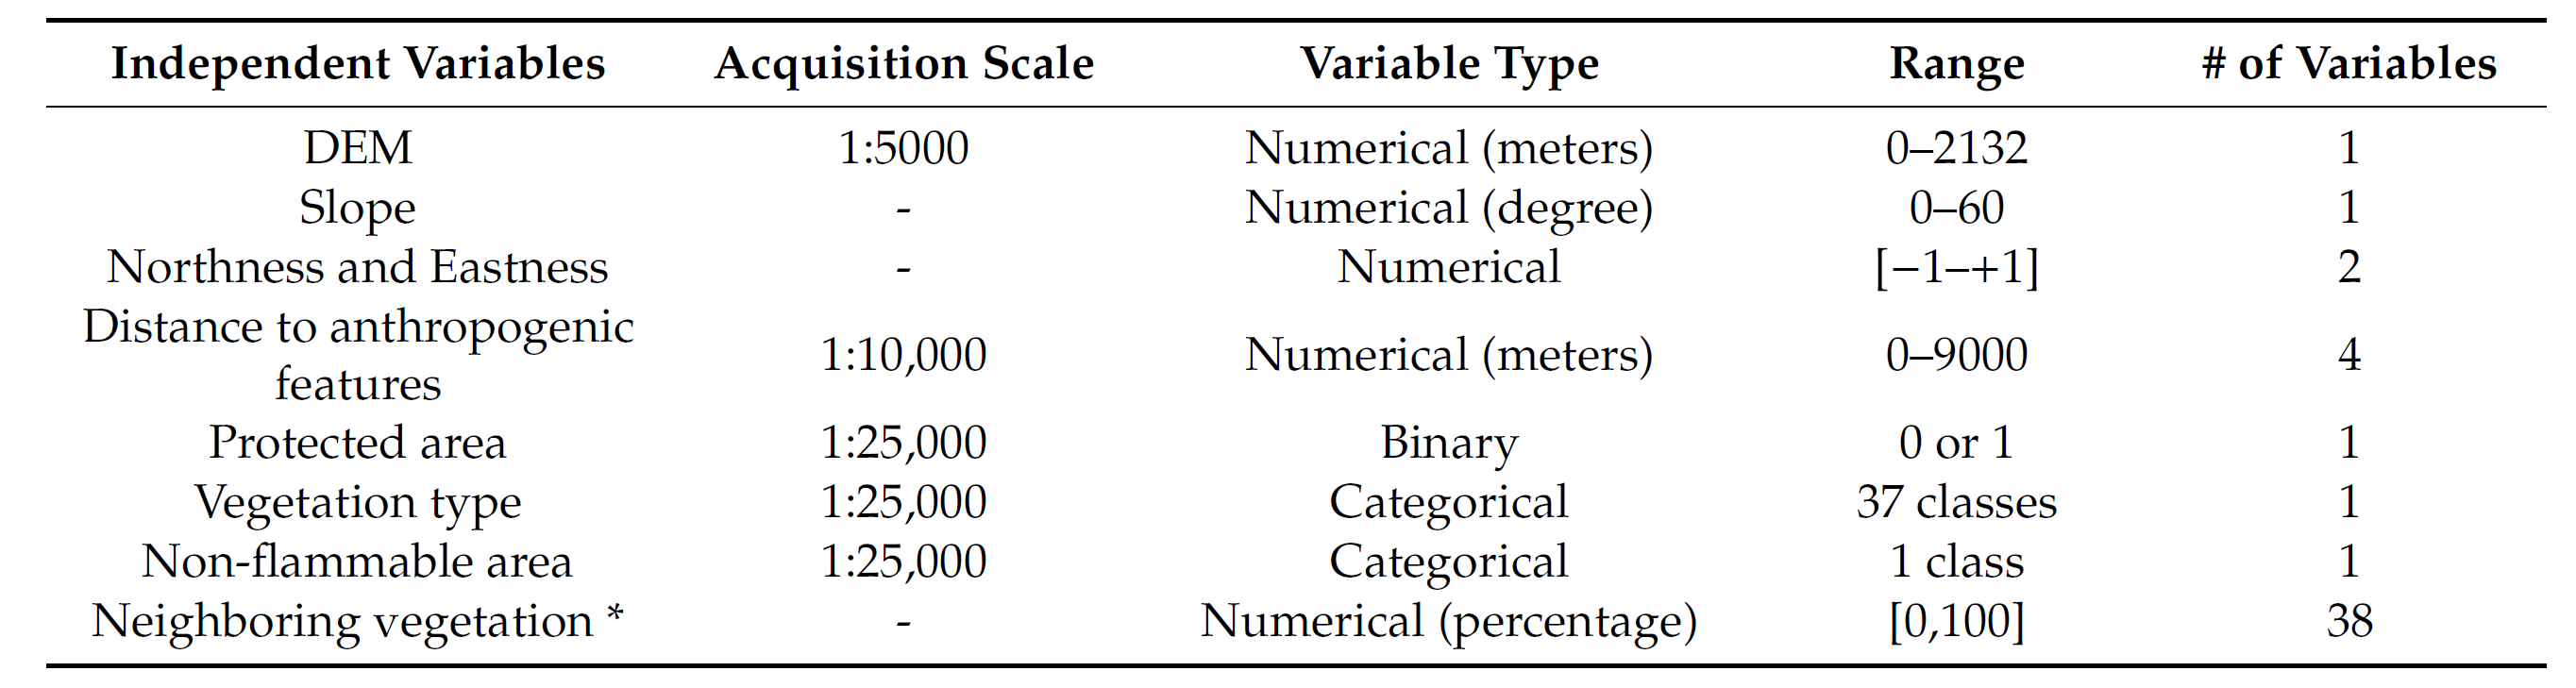

Here are some pandas commands you could use to explore your data.
[.head()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)
[.columns()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.columns.html)
[.describe()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)

In [17]:
# Exploration du jeu de données `variables`
####################################################################################################
# 1. Quel type de données contient le DataFrame « variables » ?
####################################################################################################
# Affiche les noms de toutes les colonnes (variables)
print(variables.columns)

Index(['row', 'col', 'x', 'y', 'dem', 'slope', 'north', 'east', 'veg',
       'urban_d', 'roads_d', 'crops_d', 'tracks_d', 'bioclim', 'phytoclim',
       'temp_1', 'temp_2', 'prec_1', 'prec_2', 'perc_0', 'perc_21', 'perc_22',
       'perc_23', 'perc_32', 'perc_33', 'perc_34', 'perc_37', 'point_index',
       'geometry'],
      dtype='object')


In [18]:
# Affiche les statistiques descriptives de chaque variable (nombre, moyenne, écart-type, min, quartiles, max)
print(variables.describe())

                 row            col             x             y  \
count  528669.000000  528669.000000  5.286690e+05  5.286690e+05   
mean      456.389826     962.931258  1.475397e+06  4.901395e+06   
std       240.887463     555.848154  5.558482e+04  2.408875e+04   
min         1.000000       1.000000  1.379204e+06  4.848434e+06   
25%       256.000000     491.000000  1.428204e+06  4.882034e+06   
50%       411.000000     894.000000  1.468504e+06  4.905934e+06   
75%       650.000000    1463.000000  1.525404e+06  4.921434e+06   
max       986.000000    2065.000000  1.585604e+06  4.946934e+06   

                 dem          slope          north           east  \
count  528669.000000  528669.000000  528669.000000  528669.000000   
mean      538.422731      18.021345      -0.097896       0.017473   
std       336.707659       8.175467       0.701131       0.705994   
min         0.000000       0.000000      -1.000000      -1.000000   
25%       281.000000      12.281326      -0.787887 

There are 25 columns (variables) in the DataFrame. It is probably best to start simple and just use a few variables to make the wildfire prediction.

Can we use a very simple model to predict wildfires ❓

A simple model might contain `dem`, `slope`, `veg` and `bioclim`. We can use it as a baseline to evaluate model performance when you use other combinations to train the model.

However, we cannot tell you which combination would perform the best as we have not done an extensive search while preparing the notebook.

In [19]:
# On filtre le DataFrame pour ne garder que les variables voulues comme entrées du modèle
####################################################################################################
# 1. Liste des variables à conserver
####################################################################################################
# dem = altitude (modèle numérique de terrain), slope = pente, veg = type de végétation (catégoriel), bioclim = zone bioclimatique (catégoriel)
vars_tokeep = ['dem', 'slope', 'veg', 'bioclim']

In [20]:
####################################################################################################
# 2. Crée un nouveau DataFrame 'inputs' ne contenant que ces variables
####################################################################################################
inputs = variables[vars_tokeep]   # sélection des colonnes listées dans vars_tokeep
inputs.head()   # affiche les premières lignes pour vérifier que tout fonctionne

,dem,slope,veg,bioclim
point_index,,,,
0,563,20.843185,34,15
1,527,23.599121,34,15
2,525,26.699856,34,15
3,519,24.512413,34,15
4,532,20.421495,34,15


**Q2) To avoid making inaccurate assumptions about which types of vegetation and non-flammable area are most similar, convert your categorical inputs into one-hot vectors.**

Hint 1: You may use the [`fit_transform`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html#sklearn.preprocessing.OneHotEncoder.fit_transform) method of `scikit-learn`'s [`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) class to convert categorical inputs into one-hot vectors.

Hint 2: Don't forget to remove the categorical variables from your input dataset, e.g. using [`drop`](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.html) if you are still using a `GeoDataFrame`, or [`del`](https://docs.python.org/3/reference/simple_stmts.html#the-del-statement)/[`pop`](https://docs.python.org/3/library/stdtypes.html#dict.pop) if you are working with a Python dictionary.

Hint 3: There are numerous ways to change the categorical data into one-hot vectors. It is quite easy to do in `pandas`, but scikit-learn also provides some transformers that could be useful, including [.ColumnTransformer()](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html) and [Pipeline()](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).

In the guided reading, you have seen how these functions are used. Try experiment with them and see if you prefer using these scikit transformers or pandas.

In [21]:
####################################################################################################
# 1. Importe OneHotEncoder (pour encoder 'veg' et 'bioclim') et pandas
####################################################################################################
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
####################################################################################################
# 2. Crée l'encodeur ; sparse_output=False → renvoie un tableau numpy classique (pas une matrice creuse)
####################################################################################################
enc = OneHotEncoder(sparse_output=False)

In [22]:
####################################################################################################
# 3. Convertit les variables catégorielles en vecteurs one-hot
#    (une colonne par catégorie, avec 1 si le point appartient à cette catégorie et 0 sinon)
####################################################################################################
# fit_transform apprend les catégories présentes puis encode la colonne
veg_onehot = enc.fit_transform(variables[['veg']])
bioclim_onehot = enc.fit_transform(variables[['bioclim']])
# Convertit les tableaux obtenus en DataFrames pandas
veg_transform = pd.DataFrame(veg_onehot)       # végétation
bio_transform = pd.DataFrame(bioclim_onehot)   # zone bioclimatique

In [23]:
####################################################################################################
# 4. Affiche la forme de 'veg_transform' (nombre de lignes, nombre de catégories de végétation)
####################################################################################################
print(veg_transform.shape)
# Ne pas modifier : ajoute un préfixe aux noms de colonnes (v_0, v_1... et b_0, b_1...)
# pour éviter que les colonnes des deux tableaux portent le même nom
veg_transform= veg_transform.add_prefix('v_')
bio_transform= bio_transform.add_prefix('b_')

(528669, 7)


In [24]:
####################################################################################################
# 5. Convertit 'inputs' en DataFrame pandas
####################################################################################################
inputs_gdf = pd.DataFrame(inputs).reset_index(drop=True)  # remet l'index à 0,1,2... pour qu'il corresponde aux tableaux one-hot
####################################################################################################
# 6. Ajoute 'veg_transform' et 'bio_transform' au DataFrame des entrées
####################################################################################################
inputs_gdf = inputs_gdf.join(veg_transform)   # colle les colonnes one-hot côte à côte (alignement sur l'index)
inputs_gdf = inputs_gdf.join(bio_transform)

In [25]:
####################################################################################################
# 7. Supprime avec .drop() les colonnes catégorielles d'origine 'veg' et 'bioclim' (remplacées par le one-hot)
####################################################################################################
inputs_gdf = inputs_gdf.drop(columns=['veg', 'bioclim'])
inputs_gdf.head()   # vérification visuelle

,dem,slope,v_0,v_1,v_2,v_3,v_4,v_5,v_6,b_0,b_1,b_2,b_3,b_4
0,563,20.843185,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,527,23.599121,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,525,26.699856,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,519,24.512413,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,532,20.421495,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


Now that we built our `inputs` dataset, we are ready to build our `outputs` dataset!

**Q3) Using the `point_index` column of `wildfires` and `variables`, create your `outputs` dataset, containing 1 when there was a wildfire and 0 otherwise.**

Hint: Check that `inputs` and `outputs` have the same number of cases by looking at their `.shape[0]` attribute.

In [29]:
#####################################################################################################################
# 1. Crée avec numpy un tableau de zéros de même taille que la colonne 'point_index' de variables
#    (0 = pas d'incendie par défaut)
#####################################################################################################################
outputs = np.zeros_like(variables['point_index'].to_numpy())
#####################################################################################################################
# 2. Récupère les identifiants des points où un incendie a eu lieu dans le DataFrame 'wildfires'
#####################################################################################################################
# Dans ce jeu de données, 'point_index' est l'index du GeoDataFrame (et non une colonne)
wildfiresindex = wildfires.index

In [30]:
#####################################################################################################################
# 3. Met un 1 dans le tableau de zéros aux points où un incendie s'est déclaré
#    (on pourrait le faire avec une boucle for)
#####################################################################################################################
# Version vectorisée de la boucle : les valeurs de point_index ne correspondent pas toujours à la position de la ligne,
# donc on cherche quelles lignes de `variables` ont un point_index présent dans `wildfires` (.isin renvoie True/False)
outputs[variables.index.isin(wildfiresindex)] = 1

In [31]:
#####################################################################################################################
# 4. Vérifie que `inputs` et `outputs` ont le même nombre de lignes (shape[0])
#####################################################################################################################
print(inputs_gdf.shape[0], outputs.shape[0])
print('Number of wildfire points:', outputs.sum())   # somme des 1 = nombre de points avec incendie

528669 528669
Number of wildfire points: 81834.0


**Q4) Separate your `inputs` and `outputs` datasets into a training and a test set. Keep at least 20% of the dataset for testing.**

Hint 1: You may use `scikit-learn`'s [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function.

Hint 2: If you are considering optimizing the hyperparameters of your classifier, form a validation dataset as well.

Hint 3: We recommend performing the split on the indices so that it is easier to track what points are in which dataset after splitting. You will have an easier time when plotting the susceptibility map.

In [32]:
#####################################################################################################################
# 1. Importe train_test_split() (séparation aléatoire en jeux d'entraînement et de test)
#####################################################################################################################
from sklearn.model_selection import train_test_split

In [33]:
#####################################################################################################################
# 2. Crée la liste de tous les indices des lignes : [0, 1, 2, ...]
#####################################################################################################################
all_indices = list(range(len(inputs_gdf)))

In [34]:
#####################################################################################################################
# 3. Convertit le DataFrame inputs_gdf en tableau numpy (pour pouvoir le découper avec des listes d'indices)
#####################################################################################################################
inputs_gdf = inputs_gdf.to_numpy()

In [35]:
#####################################################################################################################
# 4. Sépare aléatoirement les indices : 80 % pour l'entraînement (indx_train), 20 % pour le test (indx_test)
#    random_state=42 rend la séparation reproductible
#####################################################################################################################
indx_train, indx_test = train_test_split(all_indices, test_size=0.2, random_state=42)

In [36]:
#####################################################################################################################
# 5. Construit les jeux d'entraînement et de test à partir de ces indices
#    X = entrées (variables), y = sorties (1 = incendie, 0 = pas d'incendie)
#####################################################################################################################
X_train, X_test, y_train, y_test = inputs_gdf[indx_train], inputs_gdf[indx_test], outputs[indx_train], outputs[indx_test]

In [37]:
# Vérifie la forme des jeux d'entraînement et de test
# et s'assure qu'au moins 20 % des données sont gardées pour le test
print('Train:', X_train.shape, y_train.shape)
print('Test: ', X_test.shape, y_test.shape)
print('Test fraction:', len(indx_test) / len(all_indices))   # proportion de données dans le jeu de test

Train: (422935, 14) (422935,)
Test:  (105734, 14) (105734,)
Test fraction: 0.20000037830854467


Congratulations, you have created a viable wildfire dataset to train a machine learning classifier! 😃 Now let's get started 🔥

### Part II: Training and Benchmarking the Machine Learning Classifiers

**Q5) Now comes the machine learning fun! 🤖 Train multiple classifiers on your newly-formed training set, and make sure that at least one has the `predict_proba` method once trained.**

Hint: You may train a [`RandomForestClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) or an [`ExtraTreesClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html), but we encourage you to be creative and include additional classifiers you find promising! 💻

In [38]:
#####################################################################################################################
# 1. Importe le classifieur forêt aléatoire (Random Forest = ensemble de nombreux arbres de décision qui votent)
#####################################################################################################################
from sklearn.ensemble import RandomForestClassifier
#####################################################################################################################
# 2. Convertit X_train et X_test en DataFrames pandas
#####################################################################################################################
X_train = pd.DataFrame(X_train)
X_test = pd.DataFrame(X_test)

In [39]:
# Affiche le jeu d'entraînement pour vérifier son contenu
X_train

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,143.0,3.441056,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,204.0,21.165070,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,304.0,28.740286,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,318.0,18.950947,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,522.0,19.906359,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
422930,431.0,14.090720,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
422931,560.0,3.790979,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
422932,213.0,19.034899,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
422933,413.0,0.955438,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [40]:
#####################################################################################################################
# 3. Crée le classifieur Random Forest et l'entraîne sur le jeu d'entraînement
#    n_estimators=100 → 100 arbres ; n_jobs=-1 → utilise tous les cœurs du processeur ; random_state=42 → reproductible
#####################################################################################################################
rfc = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rfc.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [41]:
# (Optionnel) Recherche des meilleurs hyperparamètres sur un jeu de validation
# par ex. avec RandomizedSearchCV de scikit-learn

**Q6) Compare the performance and confusion matrices of your classifiers on the test set. Which classifier performs best in your case?**

Hint 1: You may use the [`accuracy_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) to quantify your classifier's performance, but don't forget there are [many other performance metrics to benchmark binary classifiers](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).

Hint 2: You can directly calculate the confusion matrix using `scikit-learn`'s [`confusion_matrix` function](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

In [42]:
#####################################################################################################################
# 1. Importe les outils d'évaluation : précision (accuracy), matrice de confusion et son affichage graphique
#####################################################################################################################
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [43]:
#####################################################################################################################
# 2. Utilise rfc pour prédire la classe (0 ou 1) de chaque point du jeu de test
#####################################################################################################################
rfc_preds = rfc.predict(X_test)

In [44]:
#####################################################################################################################
# 3. Calcule l'accuracy : proportion de prédictions correctes sur le jeu de test
#####################################################################################################################
rfc_acc = accuracy_score(y_test, rfc_preds)
print('Accuracy RF:', rfc_acc)

Accuracy RF: 0.8528477121834036


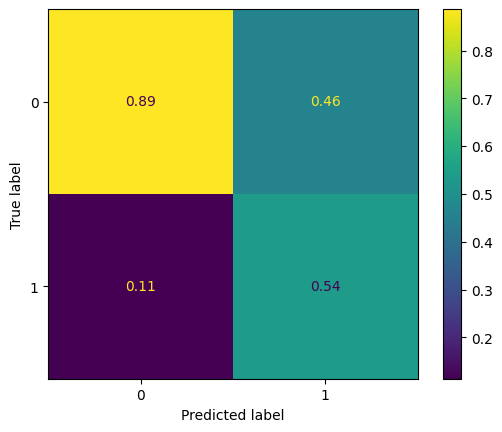

In [45]:
#####################################################################################################################
# 4. Trace la matrice de confusion (combien de vrais/faux positifs et vrais/faux négatifs)
#####################################################################################################################
cm = confusion_matrix(y_test, rfc_preds, normalize='pred')   # normalize='pred' → chaque colonne (classe prédite) est ramenée à une somme de 1
disp = ConfusionMatrixDisplay(confusion_matrix = cm)          # prépare l'affichage graphique de 'cm'
disp.plot()                                                   # dessine la matrice

For comparison, below is the confusion matrix obtained by the paper's authors:


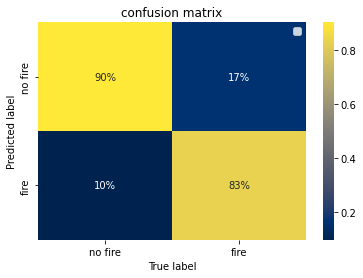

### Part III: Making the Susceptibility Map

**Q7) Using all the classifiers you trained that have a `predict_proba` method, predict the probability of a wildfire over the entire dataset.**

Hint: `predict_proba` will give you the probability of both the presence and absence of a wildfire, so you will have to select the right probability.

In [46]:
#####################################################################################################################
# 1. Prédit la probabilité d'incendie / de non-incendie sur *tout* le jeu de données
#####################################################################################################################
predprob_rf = rfc.predict_proba(pd.DataFrame(inputs_gdf))   # renvoie un tableau à 2 colonnes : [P(pas d'incendie), P(incendie)]

In [47]:
#####################################################################################################################
# 2. Extrait, pour chaque point, la probabilité qu'un incendie se produise
#####################################################################################################################
rf_testprob_fire = predprob_rf[:, 1]   # toutes les lignes, 2e colonne (indice 1) = probabilité de la classe « incendie »

**Q8) Make the susceptibility map 🔥**

Hint 1: The `x` and `y` coordinates for the map can be extracted from the `variables` dataset.

Hint 2: You can simply [`scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) `x` versus `y`, and color the dots according to their probabilities (`c`=probability of a wildfire) to get the susceptibility map.

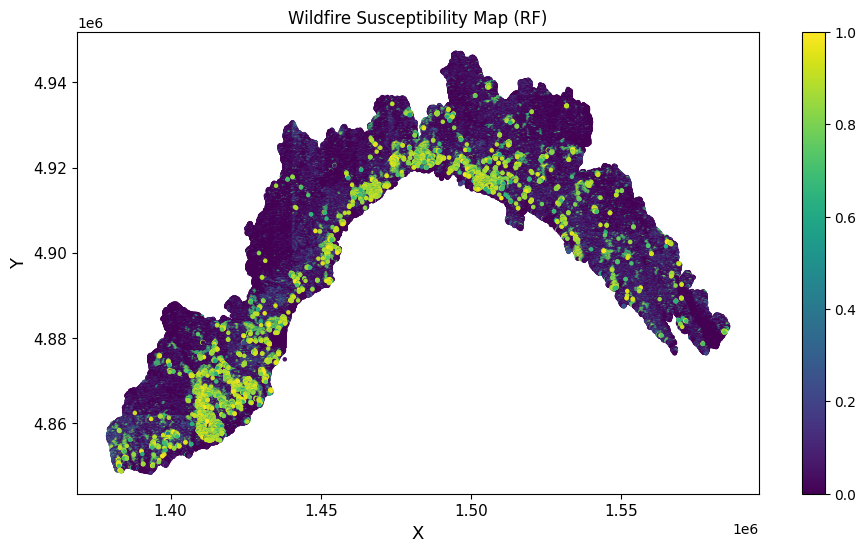

In [48]:
# Nuage de points des colonnes ['x'] et ['y'] de tout le jeu de données, coloré selon la probabilité prédite
# 'rf_testprob_fire' → c'est la carte de susceptibilité aux incendies

import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,figsize=(6+5,4+2))   # une figure de 11 × 6 pouces
# s=5 → petits points ; c=... → couleur selon la probabilité ; cmap='viridis' → palette du violet (faible) au jaune (élevée)
cmploy = ax.scatter(variables['x'],variables['y'],s=5,c=rf_testprob_fire,cmap='viridis')
plt.colorbar(cmploy,ax=ax)                    # ajoute la barre de couleurs (légende des probabilités)
ax.set_title('Wildfire Susceptibility Map (RF)')
ax.set_ylabel('Y',size=13)
ax.set_xlabel('X',size=13)
ax.tick_params(axis='both', which='major', labelsize=11)   # taille des graduations sur les deux axes
plt.show()

You should get a susceptibility map that looks like the one below. Does your susceptibility map depend on the classifier & the inputs you chose? Which map would you trust most?

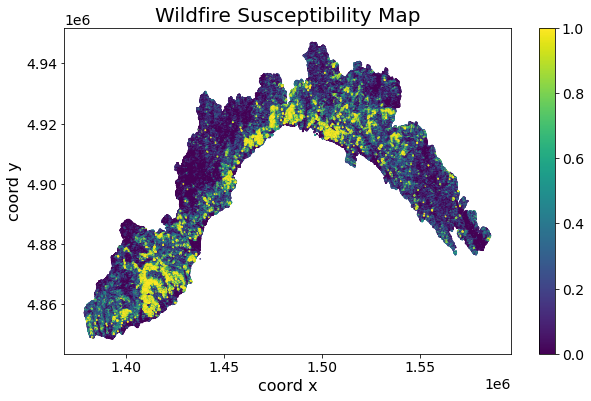

It seems like our model was too simple to generate a useful map 😞 .
Your TA actually experimented training a RandomForest model with 10 variables and got a 91% accuracy!

So you should definitely try combinations of different variables to get a map that is better than what you just got.

## Bonus Exercise 4: Exploring the Susceptibility Map's Sensitivity to Seasonality and Input Selection

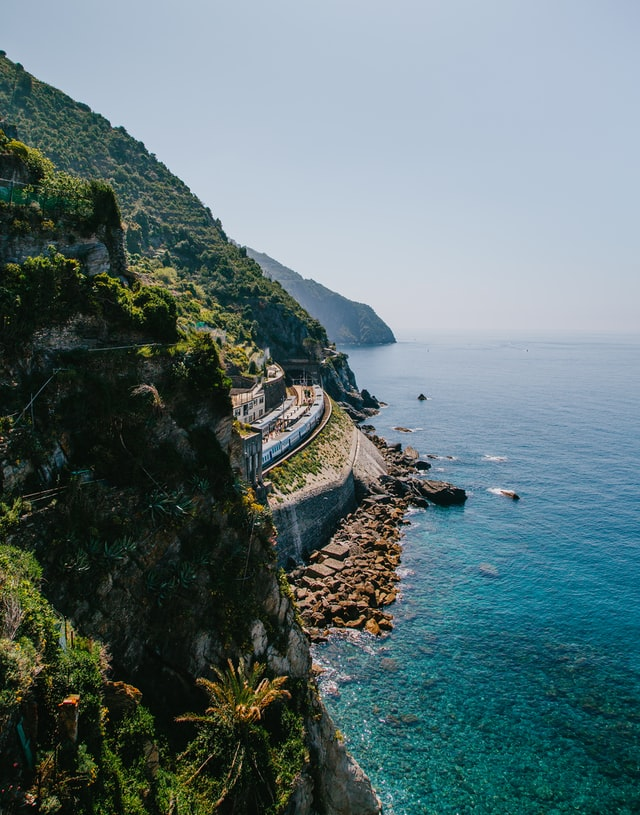

**Caption:** The Liguria region (Cinque Terre), after you save it from raging wildfires using machine learning ✌

### Part I: Seasonality

**Q1) Using the `season` column of `wildfires`, separate your data into two seasonal datasets (1=Winter, 2=Summer).**

Hint: When splitting your `inputs` into two seasonal datasets, keep in mind that `temp_1` and `prec_1` are the climatological mean temperatures and precipitation during winter, while `temp_2` and `prec_2` are the climatological mean temperature and precipitation during summer.  

In [49]:
# Identify indices for which the wildfires occured during winter/summer

In [50]:
# Use these indices to split your `inputs` and `outputs` datasets
# into two seasonal datasets

In [51]:
# Verify that for each season, the shape[0] of your
# `inputs` and `outputs` sets are the same

**Q2) Use these two seasonal datasets to make the Liguria winter and summer susceptibility maps using your best classifier(s). What do you notice?**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [52]:
# So

In [53]:
# Much

In [54]:
# Recycling

In [55]:
# Compare the winter and summer susceptibility maps

### Part II: Input Selection

The details of the susceptibility map may strongly depend on the inputs you chose from the `variables` dataset. Here, we explore two different ways of selecting inputs to make our susceptibility maps as robust as possible.

**Q3) Using your best classifier, identify the inputs contributing the most to your model's performance using [permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html).**

Hint: You may use `scikit-learn`'s [`permutation_importance` function](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html) using your best classifier as your `estimator`.

In [56]:
# Import the necessary functions and classes

In [57]:
# Calculate the permutation importance of each of your model's inputs

In [58]:
# Display the result and identify the most important inputs

**Q4) Retrain the same type of classifier only using the inputs you identified as most important, and display the new susceptibility map.**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [59]:
# Lots

In [60]:
# of

In [61]:
# recycling

In [62]:
# Make the new susceptibility map

Can you explain the differences in susceptibility maps based on the inputs' spatial distribution?

If the susceptibility map changed a lot, our best classifier may initially have learned spurious correlations. This would have affected our permutation feature importance analysis, and motivates re-selecting our inputs from scratch! 🔨

**Q5) Use the [`SequentialFeatureSelector`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SequentialFeatureSelector.html) to select the most important inputs. Select as few as possible!**

Hint: Track how the score improves as you add more and more inputs via `n_features_to_select`, and stop when it's "good enough".

In [63]:
# Import the SequentialFeatureSelector

In [64]:
# Add more and more inputs

In [65]:
# How many inputs do you need to get a "good enough" score?

Which inputs have you identified as the most important? Are they the same as the ones you selected using permutation feature importance?

**Q6) Retrain the same type of classifier using as little inputs as possible, and display the new susceptibility map.**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [66]:
# Recycle your previous code here

In [67]:
# and here

In [68]:
# And remake the final susceptibility map

How does it compare to the authors' susceptibility map below?

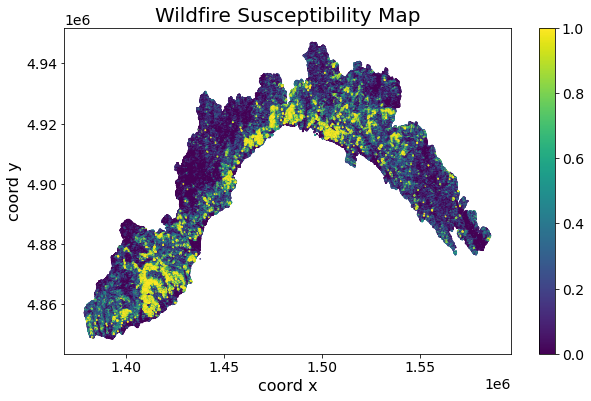